# Day 2 — Getting the Data Right (HDFS logs)

**Project:** Automatic Incident & Log Agent · **Dataset:** Loghub HDFS_v1 (575k HDFS blocks, each labelled normal/anomaly)

Each row is one HDFS *block*: how many times each of 29 log-event templates (E1..E29) appeared for it,
plus derived features and the time the block was first seen. Built by `src/logagent/data.py`.

Goals: EDA → preprocessing pipeline → imbalance strategy → leakage-free time split → a leaky-feature proof.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold, cross_val_score
from sklearn.metrics import average_precision_score, accuracy_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from logagent.splits import load_blocks, time_split, xy, FEATURES, EVENT_COLS, ROOT

sns.set_theme(style="whitegrid")
df = load_blocks()
df.head()

,block_id,E1,E2,E3,E4,E5,E6,E7,E8,E9,...,early_E25,early_E26,early_E27,early_E28,early_E29,early_elapsed,label,n_events,n_unique_events,first_ts
0,blk_-1608999687919862906,0,0,203,0,10,7,0,0,3,...,0,0,0,0,0,1.0,0,269,12,2008-11-09 20:35:18
1,blk_7503483334202473044,0,2,1,0,3,0,0,0,3,...,0,0,0,0,0,1.0,0,22,9,2008-11-09 20:35:20
2,blk_-3544583377289625738,0,0,203,0,3,0,0,0,3,...,0,0,0,0,0,2.0,1,223,9,2008-11-09 20:35:21
3,blk_-9073992586687739851,0,3,0,0,3,0,0,0,3,...,0,0,0,0,0,1.0,0,22,8,2008-11-09 20:35:23
4,blk_7854771516489510256,0,3,1,15,3,0,0,0,3,...,0,0,0,0,0,49.0,0,38,10,2008-11-09 20:35:29


## 1. EDA

In [2]:
print(df.shape)
print("anomaly rate:", f"{df['label'].mean():.3%}")
print("missing values:", int(df[FEATURES].isna().sum().sum()))
df[["n_events", "n_unique_events", "latency"]].describe().T

(575061, 65)
anomaly rate: 2.928%
missing values: 0


,count,mean,std,min,25%,50%,75%,max
n_events,575061.0,19.433815,5.177735,2.0,19.0,19.0,20.0,298.0
n_unique_events,575061.0,7.252293,1.578432,2.0,7.0,7.0,8.0,20.0
latency,575061.0,16789.470527,17886.993688,0.0,1144.0,7229.0,33680.0,54025.0


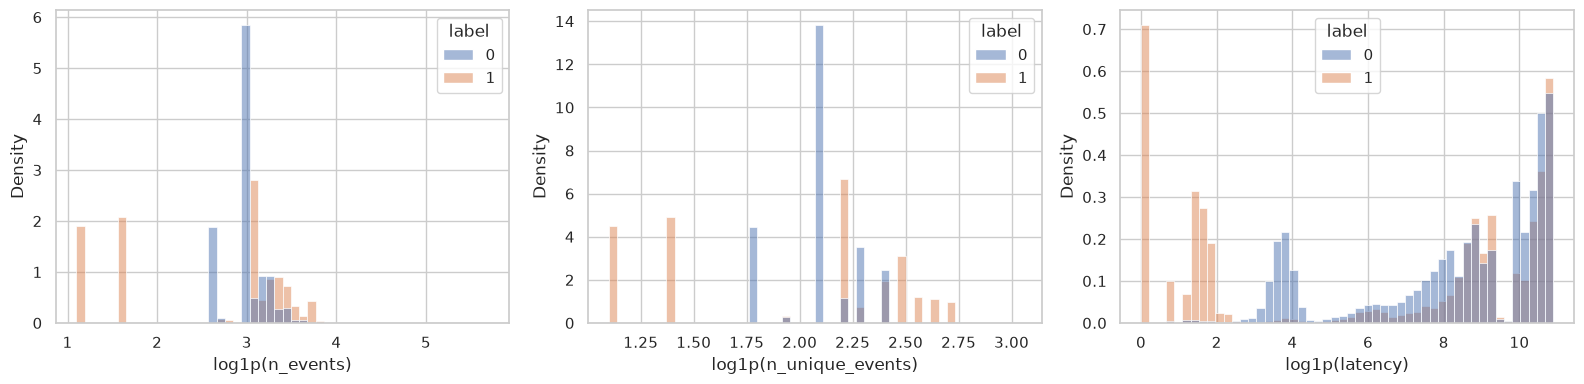

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["n_events", "n_unique_events", "latency"]):
    sns.histplot(data=df, x=np.log1p(df[col]), hue="label", stat="density", common_norm=False, bins=50, ax=ax)
    ax.set_xlabel(f"log1p({col})")
plt.tight_layout()

In [4]:
# Which events differ most between normal and anomalous blocks?
templates = pd.read_csv(ROOT / "data/raw/preprocessed/HDFS.log_templates.csv").set_index("EventId")["EventTemplate"]
rate = df.groupby("label")[EVENT_COLS].apply(lambda g: (g > 0).mean()).T
rate.columns = ["normal", "anomaly"]
rate["diff"] = rate["anomaly"] - rate["normal"]
rate["template"] = templates.reindex(rate.index).str.slice(0, 70)
rate.sort_values("diff", key=abs, ascending=False).head(10)

,normal,anomaly,diff,template
E9,1.000000,0.631370,-0.368630,[*]Received block[*]of size[*]from[*]
E26,1.000000,0.631370,-0.368630,[*]BLOCK* NameSystem[*]addStoredBlock: blockMa...
E11,1.000000,0.632914,-0.367086,[*]PacketResponder[*]for block[*]terminating[*]
E20,0.000392,0.304430,0.304038,[*]Unexpected error trying to delete block[*]B...
E25,0.003187,0.207388,0.204201,[*]BLOCK* ask[*]to replicate[*]to[*]
E18,0.003187,0.207388,0.204201,[*]Starting thread to transfer block[*]to[*]
E6,0.003185,0.205785,0.202599,[*]Received block[*]src:[*]dest:[*]of size[*]
E16,0.003185,0.205785,0.202599,[*]:Transmitted block[*]to[*]
E23,0.814510,0.613909,-0.200601,[*]BLOCK* NameSystem[*]delete:[*]is added to i...
E21,0.817333,0.617235,-0.200098,[*]Deleting block[*]file[*]


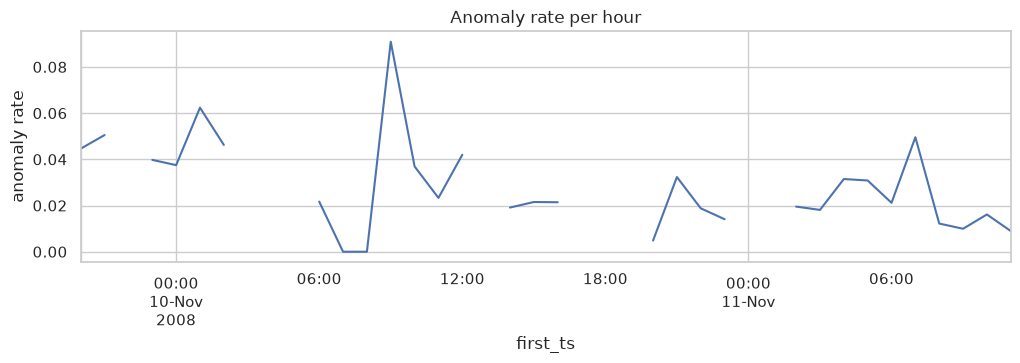

In [5]:
# Anomalies over time — important for choosing the split
hourly = df.set_index("first_ts")["label"].resample("1h").agg(["mean", "size"])
ax = hourly["mean"].plot(figsize=(12, 3), title="Anomaly rate per hour")
ax.set_ylabel("anomaly rate");

**Decisions from EDA**
- All features are numeric counts, no missing values → no imputation/encoding needed (the pipeline still documents that).
- Counts are heavily right-skewed → `log1p` + scaling for linear models (trees on Day 3 don't need it).
- ~2.9% anomalies → accuracy is meaningless; use **PR-AUC** (average precision).
- Data spans ~38 h and the anomaly rate moves over time → split **by time**, not randomly.

## 2. Preprocessing pipeline

In [6]:
prep = ColumnTransformer([
    ("num", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                      ("scale", StandardScaler())]), FEATURES),
])
logreg = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
logreg

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different

## 3. Time-based train / validation / test split
70% oldest → train, next 15% → validation, newest 15% → test. The test set is not touched until the very end (Day 3/4).

In [7]:
train, val, test = time_split(df)
for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s} rows={len(part):7,}  anomaly={part['label'].mean():.3%}  "
          f"{part['first_ts'].min()} -> {part['first_ts'].max()}")
X_tr, y_tr = xy(train); X_va, y_va = xy(val)

train rows=402,542  anomaly=3.258%  2008-11-09 20:35:18 -> 2008-11-11 06:00:46
val   rows= 86,259  anomaly=3.022%  2008-11-11 06:00:46 -> 2008-11-11 08:33:10
test  rows= 86,260  anomaly=1.294%  2008-11-11 08:33:10 -> 2008-11-11 11:04:13


In [8]:
# Cross-validation inside train: time-aware vs. stratified (shuffled)
tscv = TimeSeriesSplit(n_splits=5)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, cv in [("TimeSeriesSplit", tscv), ("StratifiedKFold", skf)]:
    s = cross_val_score(logreg, X_tr, y_tr, cv=cv, scoring="average_precision", n_jobs=-1)
    print(f"{name:16s} PR-AUC per fold: {np.round(s, 3)}  mean={s.mean():.3f}")

TimeSeriesSplit  PR-AUC per fold: [0.973 0.995 0.896 0.906 0.999]  mean=0.954


StratifiedKFold  PR-AUC per fold: [0.998 0.998 0.997 0.995 0.994]  mean=0.997


## 4. Class imbalance: why accuracy lies, and picking a strategy

In [9]:
always_normal = np.zeros_like(y_va)
print(f"'Always normal' accuracy: {accuracy_score(y_va, always_normal):.3%}  <- looks great, catches 0 anomalies")

results = {}
for name, model in {
    "no handling": Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=2000))]),
    "class_weight=balanced": logreg,
    "SMOTE": ImbPipeline([("prep", prep), ("smote", SMOTE(random_state=42)), ("clf", LogisticRegression(max_iter=2000))]),
}.items():
    model.fit(X_tr, y_tr)
    results[name] = average_precision_score(y_va, model.predict_proba(X_va)[:, 1])
pd.Series(results, name="val PR-AUC").round(4)

'Always normal' accuracy: 96.978%  <- looks great, catches 0 anomalies


no handling              0.9994
class_weight=balanced    0.9992
SMOTE                    0.9992
Name: val PR-AUC, dtype: float64

Pick the simplest strategy that performs as well as the others — usually **class weights** (no synthetic rows, nothing to leak).
SMOTE, if used, must live *inside* the pipeline so it only ever resamples training folds. The decision threshold is tuned on Day 4.

## 5. Leakage proof

**(a) The split itself can fake a score.** The CV comparison above is a real result: shuffled `StratifiedKFold` gives ~0.997,
while time-aware `TimeSeriesSplit` gives ~0.954. Shuffling lets the model train on blocks from *after* the ones it's tested on,
so tomorrow's failure patterns leak into today's prediction. The time-based split removes that optimism.

**(b) A feature that comes from the future.** Incident data often has fields that are filled in *after* the problem happened.
Below we **simulate** one: `ticket_opened`, meaning an on-call ticket was raised about the block about 2 hours after it was first seen.
(It is synthetic, so it's clearly labelled. The HDFS data has no tickets.)
To make the effect easy to see, the demo uses only two weak features (`latency`, `n_events`).

In [10]:
rng = np.random.default_rng(42)
demo = df[["first_ts", "latency", "n_events", "label"]].copy()
gets_ticket = np.where(demo["label"] == 1, rng.random(len(demo)) < 0.9, rng.random(len(demo)) < 0.005)
demo["ticket_opened_at"] = demo["first_ts"].where(gets_ticket) + pd.Timedelta(hours=2)

# Naive: "does this block have a ticket?" -- looked up today, long after the fact
demo["ticket_naive"] = demo["ticket_opened_at"].notna().astype(int)
# Point-in-time correct: "did a ticket exist at the moment we had to predict (first_ts)?"
demo["ticket_asof"] = (demo["ticket_opened_at"] <= demo["first_ts"]).astype(int)

d_tr, d_va, _ = time_split(demo)
def score(cols):
    m = Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
    m.fit(np.log1p(d_tr[cols]), d_tr["label"])
    return average_precision_score(d_va["label"], m.predict_proba(np.log1p(d_va[cols]))[:, 1])

base = ["latency", "n_events"]
pd.Series({"weak features only": score(base),
           "+ ticket (naive, LEAKY)": score(base + ["ticket_naive"]),
           "+ ticket (as of prediction time)": score(base + ["ticket_asof"])}, name="val PR-AUC").round(3)

weak features only                  0.151
+ ticket (naive, LEAKY)             0.787
+ ticket (as of prediction time)    0.151
Name: val PR-AUC, dtype: float64

The naive ticket feature makes a weak model look excellent, because it is really the answer written down later.
Computed **as of prediction time**, the ticket never exists yet, so the fake gain disappears.

**Rules:** split by time; build every feature only from information available at prediction time;
fit any statistic that touches the label on training data only, inside the pipeline.

## End-of-day checklist
- [x] EDA with decisions written down
- [x] Reusable preprocessing pipeline
- [x] Time-based train/val/test split (+ TimeSeriesSplit and StratifiedKFold CV)
- [x] Imbalance measured and a strategy chosen
- [x] Leaky feature shown to fake a high score that the honest split removes